# E67: Does a weight-side share tell a fine-tune that learned nothing from one that learned?

## The answer

The filed rule drops the overlap share on these rows and states. That is a limit of the test as much as a result, since no ordering of readings this small could have passed the band. Every update is read off the text where it learned. The pooled gap is about the size of the difference between two copy seeds. So the run shows neither that the share is informative nor that it is not.

*Independently checked: `reports/reviews/2026-11-02_review_e67-analysis.md`.*

## What we were trying to test

A fine-tune changes the weights, so Γ, the decomposition's frozen function that sets each subcomponent's causal importance, reads different activations. The user defined re-gating as "the difference in gating before and after fine-tuning". This notebook calls that change in Γ's values the switching change.

The line's existing number, r, is a share of a target token's log-odds at a trigger. It read 0.82 on a fine-tune that learned nothing, in the same range as the copy fine-tunes. So r failed that null, and it remains a candidate instrument, not a reading of mechanism. This run asks whether a reading with no target token, at every position, does better.

Nothing was trained. Every read is the do-nothing state: subcomponents unchanged, Γ frozen, the update left in Δ. The symbols, per matrix:

- $W_0$ is the original model and $\delta W$ the update.
- $a$ is $W_0$'s input to the matrix, and $C_0$ its subcomponents.
- $g_0$ and $g_1$ are Γ's values on $W_0$'s and on $W_0 + \delta W$'s activations of the same row.

We read two numbers over all positions:

- **The change in Γ's values:** the mean of $|g_1 - g_0|$ per subcomponent and position. Zero means Γ did not move. This is the first all-position reading of the user's definition, and it has no bar.
- **The overlap share:** $S_R = E\langle R, \delta W a\rangle / E\|\delta W a\|^2$, with $R = (g_1 - g_0) C_0 a$ the switching term. Zero means the switching term is orthogonal to the update's own output change, and one means it matches that change along its direction. It is signed and can pass one.

The arms, and what each rules out:

- **Two copy fine-tunes, seeds 0 and 1, step 10.** They learned to repeat a key token at a trigger, so they are the updates that did learn.
- **The fine-tune that learned nothing, steps 10 and 100.** It trained on code-heavy Pile rows and its held-out gain was slightly negative. A share that also reads high here follows any fine-tune, not learning.
- **A random update.** Each matrix gets Gaussian entries, scaled so its output change matches copy seed 0's. It rules out a reading that any update of this size produces.
- **An unchanged model, first and alone.** Every number must read exactly 0, or nothing else runs.

The rows are 128 ordinary Pile rows at 512 tokens each. Only 3 of them are as code-heavy as the text the second fine-tune trained on, so two fine-tunes are read off their tasks there. So both fine-tunes also ran on the 64 held-out rows where r failed. Trigger windows were not read.

## What we expected, and why

We leaned towards a drop, with low to medium confidence. The update enters the switching term only through $g_1$, and any update that moves the activations moves Γ. So a fine-tune that learned nothing should read like one that learned.

The filed bars are guesses with no source. A keep needs the fine-tune that learned nothing at or under 0.1, and both copy seeds at or over 0.4. A drop needs the first within 0.15 of both seeds. We guessed 0.2 to 0.6 for every fine-tune, and 0 to 0.2 for the random update.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/weight_side_read")
RUN = json.loads((ROOT / "results" / "run.json").read_text())
FIG = ROOT / "figures"

def show(name):
    display(Image(filename=str(FIG / name), width=760))

NAMES = [("ident32_s0", "copy fine-tune, seed 0", "128"), ("ident32_s1", "copy fine-tune, seed 1", "128"),
         ("code_step10", "learned nothing, step 10", "128"), ("code_step100", "learned nothing, step 100", "128"),
         ("gaussian", "random update", "128"), ("code_step10_held", "learned nothing, step 10", "64 where r failed"),
         ("ident32_s0_held", "copy fine-tune, seed 0", "64 where r failed")]
lines = ["| state | rows | overlap share | one chunk left out, spread | mean change in Γ's values |", "|---|---|---|---|---|"]
for key, label, rows in NAMES:
    s = RUN[f"state_{key}"]
    lines.append(f"| {label} | {rows} | {s['S_R']:.4f} | {s['leave_one_chunk_out']['spread']:.4f} | {s['mean_abs_dg']:.2e} |")
display(Markdown("\n".join(lines)))
print("verdict:", RUN["verdict"]["verdict"], "| zero control, matrices not exactly zero:", RUN["stage_a_zero"]["matrices_not_exactly_zero"])

| state | rows | overlap share | one chunk left out, spread | mean change in Γ's values |
|---|---|---|---|---|
| copy fine-tune, seed 0 | 128 | 0.0564 | 0.0028 | 7.74e-04 |
| copy fine-tune, seed 1 | 128 | 0.0426 | 0.0019 | 7.38e-04 |
| learned nothing, step 10 | 128 | 0.0314 | 0.0024 | 3.51e-04 |
| learned nothing, step 100 | 128 | 0.0223 | 0.0010 | 4.94e-04 |
| random update | 128 | 0.0010 | 0.0003 | 2.77e-04 |
| learned nothing, step 10 | 64 where r failed | 0.0327 | 0.0027 | 4.15e-04 |
| copy fine-tune, seed 0 | 64 where r failed | 0.0441 | 0.0034 | 5.99e-04 |

verdict: drop | zero control, matrices not exactly zero: []


## What we observed

### Does the share tell the fine-tune that learned nothing from the copy fine-tunes?

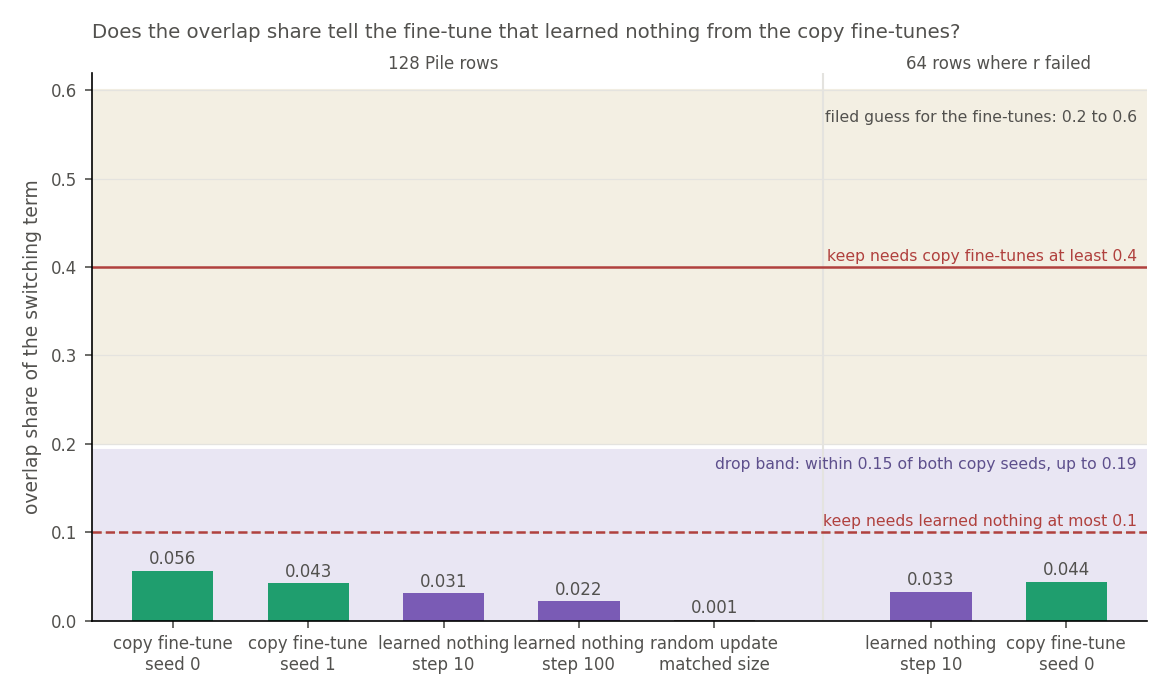

In [2]:
show("share.png")

**Reading it.** The filed rule drops the share on these rows and states. The copy fine-tunes read 0.056 and 0.043, and the fine-tune that learned nothing reads 0.031 at step 10. So the learned-nothing half of a keep holds, and the other half misses 0.4 by a factor of about eight. The reading barely moved on the rows where r failed: 0.033, against 0.044 for copy seed 0. The filed guess for the copy fine-tunes was 0.2 to 0.6, so that guess missed, while the verdict matched the lean. One caveat: the 0.15 band is wider than every reading here, so the drop is the rule firing on small numbers. The filed flag for that case fired too. Its gloss says the read sees nothing on Pile rows. This run neither confirms nor refutes that, as it has no positive control on real rows.

### Are the small shares noise, and does the loud line about the random update mean anything?

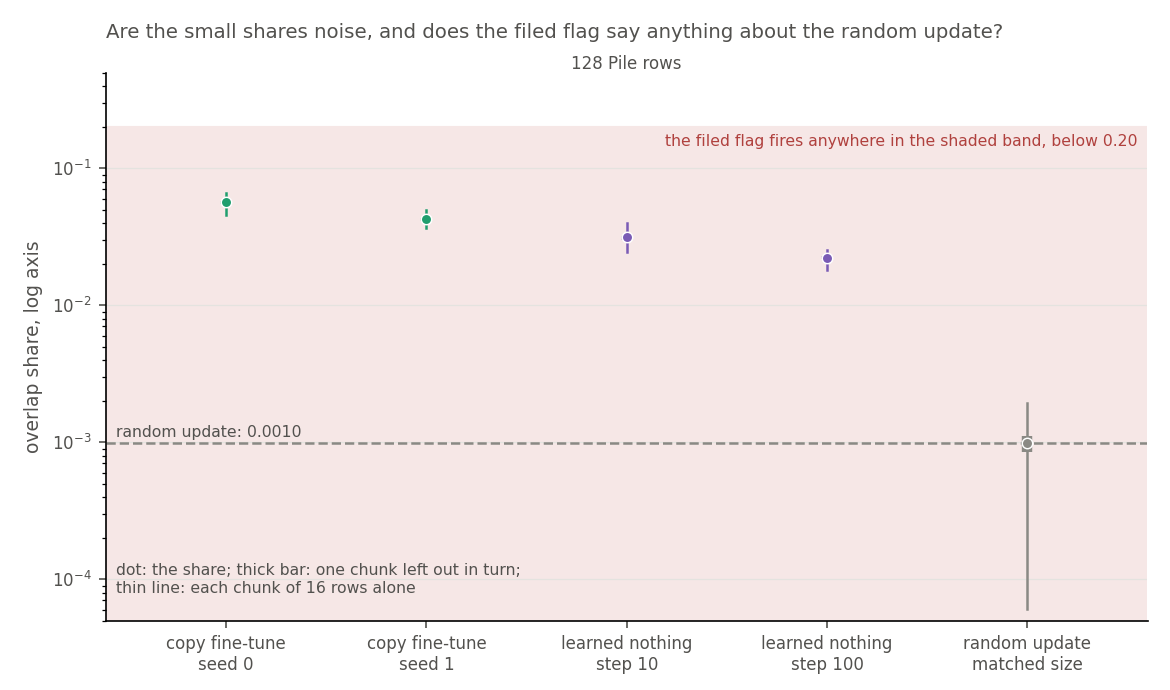

In [3]:
show("over_gaussian.png")

**Reading it.** The fine-tunes' readings are not row noise: each jackknife standard error is under a tenth of its reading. Seed noise is larger, at 0.014 across the copy seeds, and is unknown for the fine-tune that learned nothing. The loud line says nothing. The job printed "the matched Gaussian reads like the copy fine-tunes" from a filed flag: their absolute difference is at or under 0.15. That flag fires for any random reading from −0.10 to 0.20, so it fires for nearly every reading the filing guessed for a random update.

The random update was read only on these 128 rows. Its reading, 0.0010, has a standard error of about 0.0007 on a crude estimate from its 24 matrices, with one draw. So ratios to it are not stable numbers. Read the differences: 0.03 to 0.06 against about zero. Both kinds of update sit above this one draw, whose reading is near zero almost by construction. So the comparison rules out only a share that any isotropic update of this size would produce. It does not show that the share carries information about switching.

The fine-tune that learned nothing also reads above the draw, so reading above it is not a sign of learning. Whether any of the remaining gap to the copy fine-tunes follows learning is not tested here.

Γ's values moved 0.37 as far on the random update as on the copy fine-tunes, while the share fell to about zero. The size of the switching term was not measured, so this does not split into size and alignment.

The thick bars are the spread the job saved: the range of the share over leaving out each chunk of 16 rows in turn. Over every state read, it is at most 0.0034. It is not a standard error, and it shrinks as chunks are added: the same chunks alone span up to 0.020. The two copy seeds differ by 0.014, more than any such spread, and more than the 0.011 gap between seed 1 and step 10.

### How far do Γ's values move, for an update of a given size?

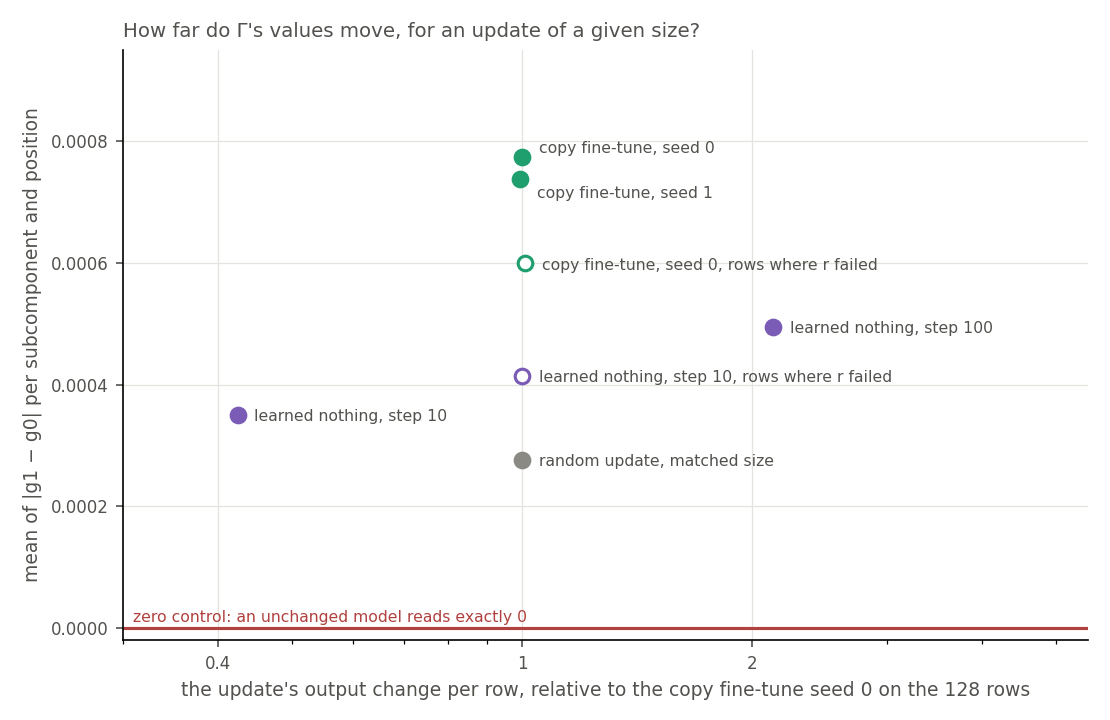

In [4]:
show("gamma_change.png")

**Reading it.** Γ's values move on every update, and half to two thirds as far on the fine-tune that learned nothing. This is report-only, since no bar was filed. The copy fine-tunes read 0.00077 and 0.00074, and the fine-tune that learned nothing 0.00035 and 0.00049. The random update reads 0.00028, and the unchanged model exactly 0.

Size alone does not explain the gap on these rows. The figure's axis is the squared output change: step 10's is 0.42 of copy seed 0's and step 100's is 2.1 of it. In size that is 0.65 and 1.46, and both read below. On the rows where r failed the two squared output changes match within 1%, and step 10 reads 0.69 of copy seed 0.

So a moved Γ is not by itself evidence of learning. The noise floor is thin: two copy seeds, one learned-nothing seed, one random draw. The mean also runs over all 38,912 subcomponents, about three quarters of them dead, and counts a moved value in full even where its subcomponent's activation is zero.

### Does any single matrix read differently from the pooled share?

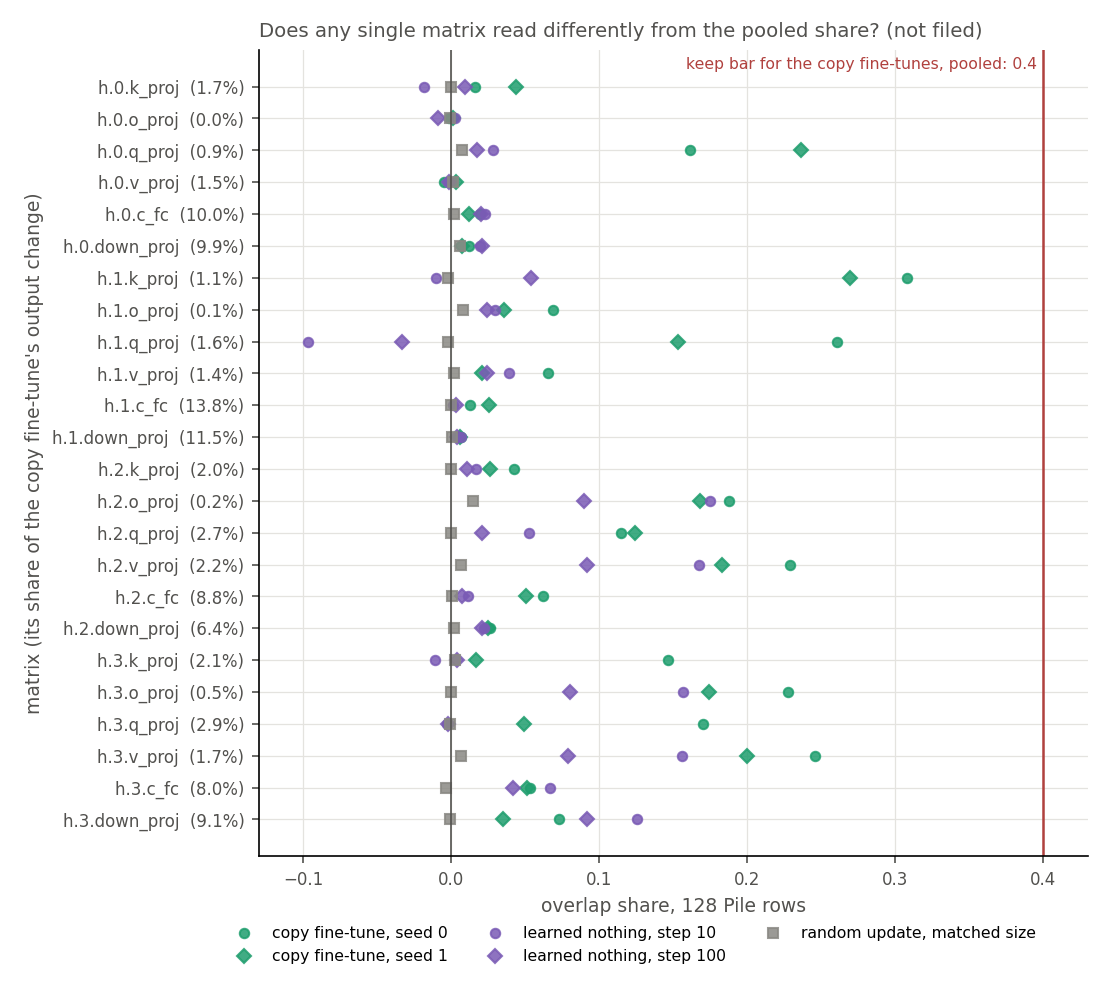

In [5]:
show("per_matrix.png")

**Reading it.** No filed rule reads this. As arithmetic, most of the pooled gap comes from attention matrices. It cannot be read as learning against no learning: the two kinds of update also differ in task, data and shape, the code side has one seed, and per-matrix shares have no noise floor. The highest reading is 0.31, on block 1's key matrix. Pooled over attention matrices, the copy fine-tunes read 0.146 and 0.102, against 0.034 and 0.021 for the fine-tune that learned nothing. Pooled over MLP matrices, the four readings are alike, at 0.023 to 0.031. That hides gaps of opposite sign on single MLP matrices. MLP matrices hold 65 to 78% of the denominator, which pulls the pooled share towards their low readings. The 24 matrices also leave room for a chance pattern.

## What we learned

The re-gating line gains no new instrument here, and the split side will not be added. This is a drop on 128 Pile rows and 64 code-heavy rows, on these saved do-nothing states. It does not say that the weight side never works, and the run shows neither that the share is informative nor that it is not. No state learned anything on the rows read, so the run does not test learning where learning shows. The first all-position reading of the user's definition shows Γ's values moving on a fine-tune that learned nothing. They moved half to two thirds as far as on the copy fine-tunes. None of this reads mechanism: elicitation is mechanistic in this project, and a label comes from a causal check, which no number here is. The known limit also stands: a new mechanism built from subcomponents $W_0$ already has reads as elicited to VPD.

## How compelling is the evidence

- **No positive control on real rows.** The share has only a unit test. There, a value moved by 1 on the subcomponent equal to the update reads 1, and on one writing elsewhere reads 0. The zero control and the dead-read stop show the read is live, not correct. A wrong $g_1$ that still moved could also land on this verdict.
- **Blind to behaviour and to size.** There is no token and no loss. A large switching term orthogonal to the update reads 0, so a small share does not mean a small switching term.
- **One $a$ per matrix.** It is $W_0$'s, so an upstream update reaches the read only through $g_1$.
- **Off task.** The copy fine-tunes are off task on every row read. The fine-tune that learned nothing is near its text only on the 64 rows.
- **Thin on seeds.** Two copy seeds, one seed of the fine-tune that learned nothing, one random draw, one Γ.

## Surprises

The fine-tune readings came in far under the guess, not narrowly: 0.02 to 0.06 against a guessed 0.2 to 0.6. I cannot explain the size of that miss, as the guess had no source. The loud line fired, and it is empty for the reason above. Most of the pooled gap coming from attention matrices is post hoc, and confounded with the copying task. The job took 1 minute 29 seconds against an estimate of 5 to 10 minutes.

## What next

The filed step for a drop: "the idea goes to TRIED.md as dropped; the all-position reading of Γ's change stands by itself. The split side is never added". That is done, and no new run follows from this report.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| verdict | the share separates the two kinds of update | keep: code ≤ 0.1 and copy ≥ 0.4; drop: within 0.15 of both seeds | gaps 0.025, 0.011 at step 10; 0.034, 0.020 at step 100 | `drop`, as leaned |
| `drop_both_small` | all readings small | code and both seeds ≤ 0.1 | 0.031, 0.056, 0.043 | fired |
| `gaussian_like_copy` | the random update reads like the copy fine-tunes | absolute difference ≤ 0.15 | 0.049 | fired, says nothing here |
| `held_rows_fail` | code step 10 over 0.1 on the rows where r failed | only takes back an adopting label | 0.033 | false |
| control | an unchanged model reads exactly 0 | every matrix, one chunk | all 24 exact | pass |
| guess | copy S_R 0.2 to 0.6 | not a rule | 0.056, 0.043 | missed |
| guess | code S_R 0.2 to 0.6 | not a rule | 0.031, 0.022 | missed |
| guess | random S_R 0 to 0.2 | not a rule | 0.0010 | held |

## Not run

- The split side: the least-squares state, its direct, interaction and residual terms, and the students. A drop never reads it.
- A weight-side column for E58 or E62.
- The same read on task windows, or on the fine-tune that did learn on Pile.
- The size of the switching term, a second random draw, a second seed of the fine-tune that learned nothing.
- The zero control on the rows where r failed.

## Departures from the literature

Γ runs in fp32, where the authors' setting is bf16, because the update is 1 to 2% of the weights. The authors trained Γ on $W_0$; reading it on $W_0 + \delta W$'s activations is this project's do-nothing operation. No other source is used, and the filed bars have none.

## Provenance

Results: `experiments/weight_side_read/results/run.json`. Rules: `results/predictions.json`. Full record: `reports/analyses/2026-11-02_analysis_e67-weight-side.md`. MATS cluster, NVIDIA L40, `debug` QoS, job 49342, exit 0, 1 minute 29 seconds, $0.